In [2]:
# Data libraries

import pandas as pd
import numpy as np

# Plotting libraries
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib import image as mpimg

# sklearn modules
import sklearn

# Load data  
df_avg = pd.read_csv("csv_files/avg_river_levels.csv")
df_min = pd.read_csv("csv_files/min_river_levels.csv")
df_max = pd.read_csv("csv_files/max_river_levels.csv")
df_locs = pd.read_csv("csv_files/monitoring_locations.csv")

df_min.head()

,County,Station_Name,Observation_ID,05/10/2014,06/10/2014,07/10/2014,08/10/2014,09/10/2014,10/10/2014,13/10/2014,...,29/09/2026,30/09/2026,01/10/2026,02/10/2026,03/10/2026,04/10/2026,05/10/2026,06/10/2026,07/10/2026,08/10/2026
0,aberdeenshire,"Bogie, Redcraig",aberdeenshire__bogie-redcraig__obs1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.13,0.13,0.15,0.14,0.13,0.13,0.12,0.12,0.12,0.12
1,aberdeenshire,"Dee (Grampian), Mar Lodge",aberdeenshire__dee-grampian-mar-lodge__obs1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.71,0.71,0.77,0.75,0.78,0.74,0.71,0.68,0.67,0.66
2,aberdeenshire,"Dee (Grampian), Park",aberdeenshire__dee-grampian-park__obs1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.89,0.88,1.07,0.95,0.95,0.94,0.91,0.87,0.84,0.83
3,aberdeenshire,"Dee (Grampian), Polhollick",aberdeenshire__dee-grampian-polhollick__obs1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.46,0.46,0.57,0.51,0.53,0.50,0.48,0.45,0.43,0.42
4,aberdeenshire,"Dee (Grampian), Woodend",aberdeenshire__dee-grampian-woodend__obs1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.54,0.54,0.71,0.61,0.61,0.60,0.57,0.53,0.50,0.49


In [5]:
# Load data  

# Merge into one useful dataframe 
id_cols = ['County', 'Station_Name', 'Observation_ID']
date_cols = [c for c in df_avg.columns if c not in id_cols]

def melt_river_data(df, value_name):
    """ Converts wide format (dates as columns) to long format (dates as rows)"""
    melted = df.melt(
        id_vars=id_cols, 
        value_vars=date_cols, 
        var_name='Date', 
        value_name=value_name
    )
    return melted

df_avg_long = melt_river_data(df_avg, 'Avg_Level')
df_min_long = melt_river_data(df_min, 'Min_Level')
df_max_long = melt_river_data(df_max, 'Max_Level')

# Merge long format df_min and long format df_avg
df_combined = pd.merge(
    df_avg_long, 
    df_min_long, 
    on=id_cols + ['Date'],  
    how='outer'             
)

# Then merge result with long format df_max 
df_combined = pd.merge(
    df_combined, 
    df_max_long, 
    on=id_cols + ['Date'], 
    how='outer'
)

# Finally merge with df_locs
df_combined = pd.merge(
    df_combined,
    df_locs,
    on=id_cols,
)

df_combined.head()

,County,Station_Name,Observation_ID,Date,Avg_Level,Min_Level,Max_Level,Latitude,Longitude
0,aberdeenshire,"Bogie, Redcraig",aberdeenshire__bogie-redcraig__obs1,01/01/2015,NaN,NaN,NaN,57.424758,-2.802015
1,aberdeenshire,"Bogie, Redcraig",aberdeenshire__bogie-redcraig__obs1,01/01/2016,NaN,NaN,NaN,57.424758,-2.802015
2,aberdeenshire,"Bogie, Redcraig",aberdeenshire__bogie-redcraig__obs1,01/01/2017,NaN,NaN,NaN,57.424758,-2.802015
3,aberdeenshire,"Bogie, Redcraig",aberdeenshire__bogie-redcraig__obs1,01/01/2018,0.431,0.391,0.475,57.424758,-2.802015
4,aberdeenshire,"Bogie, Redcraig",aberdeenshire__bogie-redcraig__obs1,01/01/2019,0.221,0.217,0.226,57.424758,-2.802015


avg is missing 525,877 values (30.61%)
min is missing 525,877 values (30.61%)
max is missing 525,877 values (30.61%)


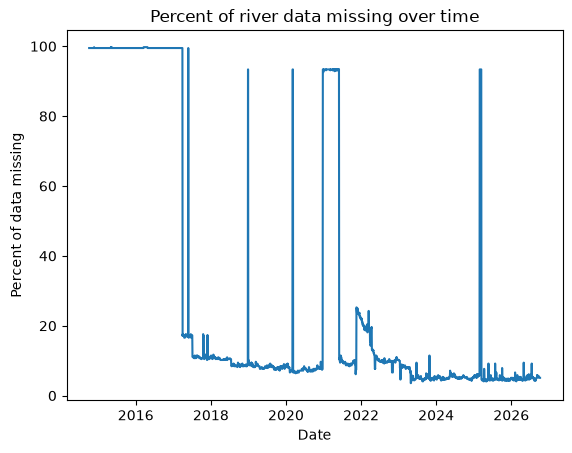

NameError: name 'df_combined' is not defined

In [3]:
for name, df in [("avg", df_avg), ("min", df_min), ("max", df_max)]:
    missing = df.isna().sum().sum()
    total = df.size
    print(f"{name} is missing {missing:,} values ({missing / total * 100:.2f}%)")


#plotting the missing values againt date
missing = df_avg.iloc[:, 3:].isna().mean(axis=0) * 100

plt.plot(pd.to_datetime(missing.index, dayfirst=True), missing)
plt.xlabel("Date")
plt.ylabel("Percent of data missing")
plt.title("Percent of river data missing over time")
plt.show()


df_combined['Date'] = pd.to_datetime(df_combined['Date'], format='%d/%m/%Y')




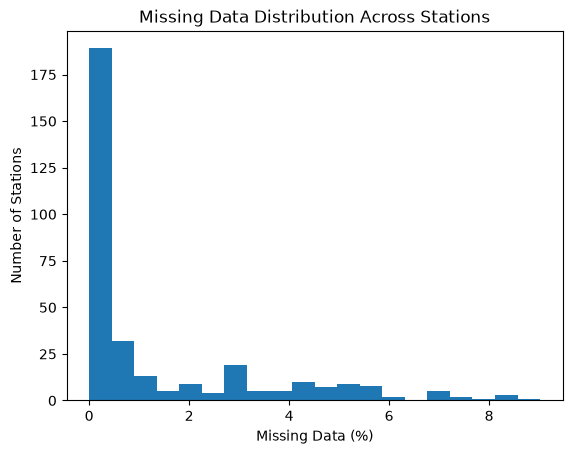

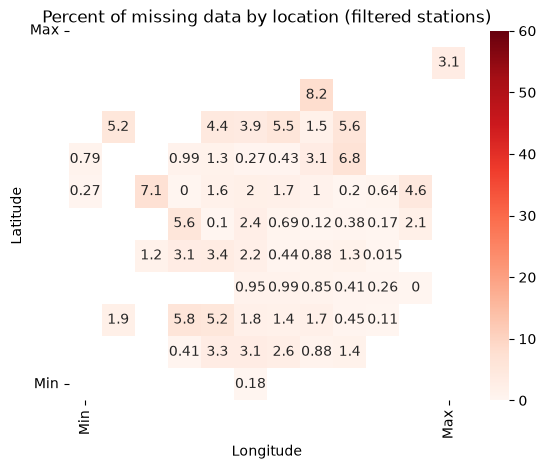

Observation_ID
aberdeenshire__bogie-redcraig__obs1               0.000000
aberdeenshire__dee-grampian-mar-lodge__obs1       0.151837
aberdeenshire__dee-grampian-park__obs1            0.030367
aberdeenshire__dee-grampian-polhollick__obs1      0.091102
aberdeenshire__dee-grampian-woodend__obs1         0.212572
                                                    ...   
wigtown__port-erin-wigtown__obs2                  3.310052
wigtown__portpatrick-wigtown-tidal-level__obs2    3.067112
wigtown__portpatrick-wigtown__obs1                3.067112
wigtown__water-of-luce-airyhemming__obs1          1.973884
wigtown__water-of-minnoch-minnoch-bridge__obs1    0.242940
Length: 329, dtype: float64

In [9]:
#Work withdata in wide form

dates = pd.to_datetime(df_avg.columns[3:], dayfirst=True)   # dd/mm/yyyy strings
vals = df_avg.iloc[:, 3:].copy()
vals.columns = dates
vals.index = df_avg["Observation_ID"]        # or Station_Name, if it's unique
vals = vals.T                                # rows = dates, columns = stations

# full daily data with NA rows where gaps were 
vals = vals.reindex(pd.date_range(vals.index.min(), vals.index.max(), freq="D")) 

# drop bigoutage days 
good = vals[vals.isna().mean(axis=1) <= 0.5] # compute for each date fraction of stations missing,get rid of dates with more than 50% missing

# drop stations that are missing too much of what's left
miss = good.isna().mean()
keep = miss.index[miss <= 0.1]        
filtered = good[keep]

miss_fil = filtered.isna().mean() * 100

#histogram 
plt.hist(miss_fil, bins=20)
plt.xlabel("Missing Data (%)")
plt.ylabel("Number of Stations")
plt.title("Missing Data Distribution Across Stations")
plt.show()

#heatmap
df_map = df_locs.copy()
df_map.index = df_avg["Observation_ID"]          
df_map["Missing"] = miss_fil          

df_map["Latitude"] = pd.cut(df_map["Latitude"], bins=12, ordered=True)
df_map["Longitude"] = pd.cut(df_map["Longitude"], bins=12)

heatmap_data = df_map.pivot_table(values="Missing", index="Latitude",
                                  columns="Longitude", observed=False)
sns.heatmap(heatmap_data, annot=True, cmap="Reds", vmin=0, vmax=60)
plt.title("Percent of missing data by location (filtered stations)")
plt.xticks([0.5, 11.5], ["Min", "Max"])
plt.yticks([0.5, 11.5], ["Min", "Max"])
plt.gca().invert_yaxis()
plt.show()

miss_fil
